### Random Forests and Photo-zs

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [33]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 100

In [2]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [3]:
#!pip install astropy
import astropy

from astropy.io import fits


#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [4]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
    arr = np.asarray(data[1].data)
    arr = arr.byteswap().view(arr.dtype.newbyteorder('='))
    df = pd.DataFrame(arr) 
    #https://numpy.org/doc/2.1/user/byteswapping.html

In [5]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [6]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,b'',b'',b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',b'',b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,b'',-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',b'',b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,b'',-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',b'',b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,b'',-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',b'',b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,b'',-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [7]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [8]:
features=['u_apercor','g_apercor','r_apercor','i_apercor','z_apercor','y_apercor']
features=df[features]

In [9]:
features

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980
...,...,...,...,...,...,...
23817,25.255430,25.056985,24.334668,24.383588,24.093228,-99.000000
23818,25.430378,24.728811,24.308648,24.014960,24.286921,-99.000000
23819,24.284426,24.378531,24.250438,23.943026,23.373493,-99.000000
23820,24.522067,24.366465,23.722660,23.457544,23.267684,-99.000000


In [10]:
target=df['zhelio']
target

0        1.115261
1        0.290608
2        0.605744
3        1.306796
4        0.957669
           ...   
23817    0.579505
23818    1.153363
23819    0.913567
23820    0.520135
23821    0.513979
Name: zhelio, Length: 23822, dtype: float32

### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction](https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA)

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [11]:
model = RandomForestRegressor()

In [12]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [13]:
%%time
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(model, features, target, cv = cv, return_train_score=True)

CPU times: user 43.4 s, sys: 270 ms, total: 43.6 s
Wall time: 43.8 s


In [14]:
scores

{'fit_time': array([11.55197144,  7.5039978 ,  7.47948098,  7.55969429,  7.50908828]),
 'score_time': array([0.10433125, 0.10364485, 0.10413027, 0.10397696, 0.10458899]),
 'test_score': array([0.34255629, 0.30015784, 0.29159016, 0.32302384, 0.30315224]),
 'train_score': array([0.87814251, 0.87633209, 0.87492057, 0.87632225, 0.87524352])}

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [16]:
print('test mean:',scores['test_score'].mean())
print('test std:',scores['test_score'].std())
print('train mean:',scores['train_score'].mean())
print('train std:',scores['train_score'].std())




test mean: 0.31209607201723627
test std: 0.0183861193269803
train mean: 0.8761921899453611
train std: 0.0011275849861093173


**Qué puede decir de este resultado? Hay bias alto o varianza alta?**
- Obtuvimos un valor de train mucho mayor al de test, por lo que podemos decir que hay una alta varianza, o un overfitting

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [18]:
ypred = cross_val_predict(model, features, target, cv = cv)

(0.0, 3.0)

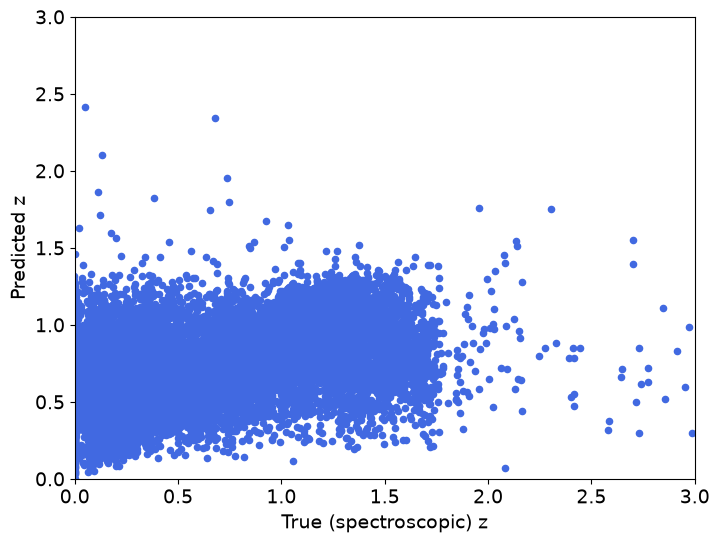

In [39]:
plt.figure(figsize=(8,6))
plt.scatter(target,ypred, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
#plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha. 

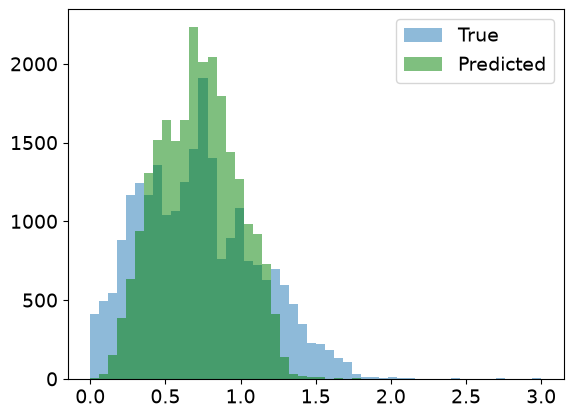

In [40]:
plt.hist(target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

**Outlier fraction**

In [45]:
z_phot = ypred
z_spec = target
delta_z = z_phot - z_spec

eta = np.sum(np.abs(delta_z) > 0.15/(1 + z_spec ))/len(z_spec)
print(eta)

0.48879187305851735


y NMAD

In [47]:
MAD = np.median(np.abs(delta_z)/ (1 + z_spec))
NMAD = 1.48*MAD
print(NMAD)

0.07368535185180691


### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [48]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False) #sample sin reemplazo 

In [49]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [50]:
seld = features.loc[sel,:]
selt = target[sel]

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [51]:
littlescores = cross_validate(model,seld,selt, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

In [52]:
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(np.float64(0.27762715338769406), np.float64(0.8763722031531694))

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?



#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [53]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper 

- min_impurity_decrease 

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [54]:
%%time
#Toma algunos minutos
parameters = {'min_impurity_decrease':[0.1, 0.5, 0.0], \
              'max_features':[None,4,2], 'n_estimators':[50, 100, 200], 'min_samples_split': [10,20,100], 
              'max_leaf_nodes':[None, 100, 200]}
#... implemente el resto

grid_search = GridSearchCV(estimator=RandomForestRegressor(random_state=42), param_grid=parameters,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),scoring='r2',n_jobs=-1,verbose=1)

grid_search.fit(seld, selt)

print("Mejores hiperparámetros:", grid_search.best_params_)
print("Mejor score R2:", grid_search.best_score_)

best_model = grid_search.best_estimator_

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
Mejores hiperparámetros: {'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 20, 'n_estimators': 200}
Mejor score R2: 0.29416955901558833
CPU times: user 9.35 s, sys: 1.47 s, total: 10.8 s
Wall time: 4min 45s


Guardamos el resultado en un dataframe y buscamos el mejor modelo 

In [58]:
scores = pd.DataFrame(grid_search.cv_results_)
scoresCV = scores[['params','mean_test_score','std_test_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)


In [59]:
scoresCV

,params,mean_test_score,std_test_score
104,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.294170,0.033395
181,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.292811,0.032999
101,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.292688,0.036378
103,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.292368,0.034939
185,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.291691,0.027632
...,...,...,...
221,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.1, 'min_samples_split': 20...",-0.001818,0.001907
224,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.1, 'min_samples_split': 10...",-0.001818,0.001907
233,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.5, 'min_samples_split': 10...",-0.001818,0.001907
227,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.5, 'min_samples_split': 10...",-0.001818,0.001907


### Mejoran los scores?
- Casi siguen iguales

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [60]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]



In [61]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [62]:
mags.shape

(23822, 9)

In [63]:
#zquality - solo usa objetos con medición de redshift de buena calidad

mags = mags[mags['zquality'] >= 3]

mags.shape

(16857, 9)

In [64]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data

mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [65]:
mags = mags[mags > -10].dropna()

In [66]:
mags.shape

(6371, 9)

In [67]:
mags = mags[mags < 90].dropna()

In [68]:
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [69]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [70]:
sel_target = target[sel_features.index]

**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.** 

In [84]:
scores_new = cross_validate(model, sel_features, sel_target, cv=cv, return_train_score=True)
scores_new

{'fit_time': array([1.04857683, 0.77106619, 0.57151699, 0.47081923, 0.50515199]),
 'score_time': array([0.03787351, 0.02565432, 0.02621365, 0.02464986, 0.02504349]),
 'test_score': array([0.84067356, 0.85108328, 0.64233911, 0.7028698 , 0.72708696]),
 'train_score': array([0.96076378, 0.95972814, 0.96696267, 0.96455159, 0.96262374])}

In [83]:
print(f"Test R2 (Promedio): {scores_new['test_score'].mean():.4f}")
print(f"Train R2 (Promedio): {scores_new['train_score'].mean():.4f}")



Test R2 (Promedio): 0.7518
Train R2 (Promedio): 0.9642


In [74]:
parameters = {
    'min_impurity_decrease': [0.0, 0.01, 0.1], 
    'max_features': [1.0, 'sqrt', 4, 2], 
    'n_estimators': [50, 100, 200], 
    'min_samples_split': [10, 20], 
    'max_leaf_nodes': [None, 100, 200]
}

grid_search_new = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=parameters,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search_new.fit(sel_features, sel_target)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_features': [1.0, 'sqrt', ...], 'max_leaf_nodes': [None, 100, ...], 'min_impurity_decrease': [0.0, 0.01, ...], 'min_samples_split': [10, 20], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about

In [77]:
ypred_new = cross_val_predict(model, sel_features, sel_target, cv=cv)

In [79]:
delta_z_new = ypred_new - sel_target
eta_new = np.sum(np.abs(delta_z_new) > 0.15 / (1 + sel_target)) / len(sel_target)
sigma_nmad_new = 1.48 * np.median(np.abs(delta_z_new / (1 + sel_target)))

print(f"Fracción de outliers: {eta_new:.4f}")
print(f"sigma_NMAD: {sigma_nmad_new:.4f}")

Fracción de outliers: 0.2421
sigma_NMAD: 0.0356


(0.0, 3.0)

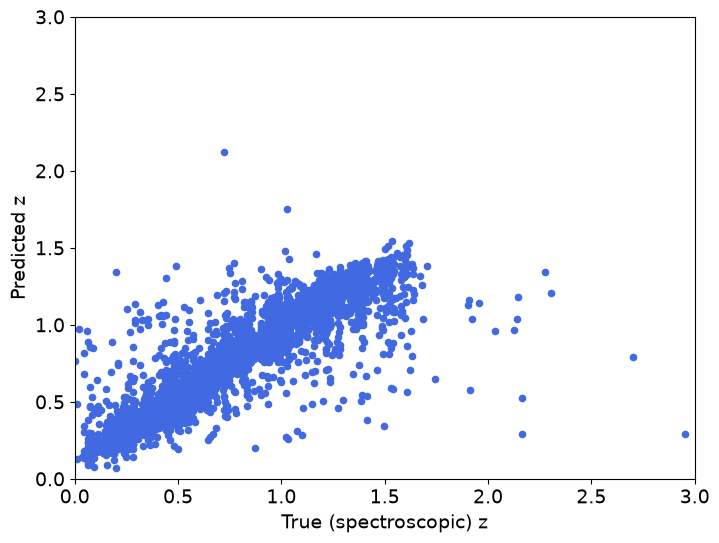

In [80]:
plt.figure(figsize=(8,6))
plt.scatter(sel_target,ypred_new, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
#plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Conclusion: Cómo se compara nuestro modelo con el resultado del paper? 
- Se observa que la "nube" dispersa de puntos se ha reducido considerablemente. Los puntos ahora siguen una clara diagonal ascendente, lo que indica una correlación mucho más fuerte entre el reshift fotométrico predicho y el espectroscópico real

Revise la sección 7 del paper. Podemos mejorar nuestro modelo aún más? Implemente un nuevo modelo con la mejora identificada
- Podriamos mejorarlo considerando la diferencia de brillo entre los filtros


In [81]:
features_colors = pd.DataFrame()
features_colors['u_g'] = sel_features['u_apercor'] - sel_features['g_apercor']
features_colors['g_r'] = sel_features['g_apercor'] - sel_features['r_apercor']
features_colors['r_i'] = sel_features['r_apercor'] - sel_features['i_apercor']
features_colors['i_z'] = sel_features['i_apercor'] - sel_features['z_apercor']
features_colors['z_y'] = sel_features['z_apercor'] - sel_features['y_apercor']

model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores_color = cross_validate(model, features_colors, sel_target.reset_index(drop=True), cv=cv, return_train_score=True)

print(f"Test R2 (Promedio): {scores_color['test_score'].mean():.4f}")
print(f"Train R2 (Promedio): {scores_color['train_score'].mean():.4f}")

ypred_color = cross_val_predict(model, features_colors, sel_target.reset_index(drop=True), cv=cv)

Test R2 (Promedio): 0.7998
Train R2 (Promedio): 0.9705


(0.0, 3.0)

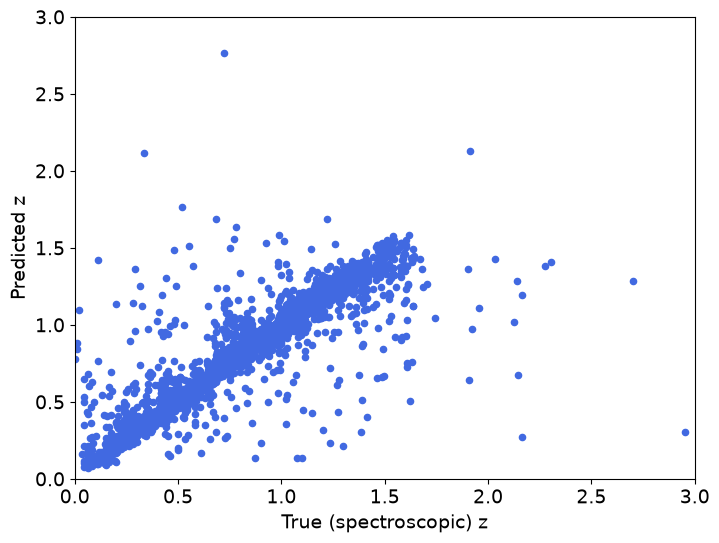

In [82]:
plt.figure(figsize=(8,6))
plt.scatter(sel_target,ypred_color, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
#plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

La combinación de una limpieza de datos basada en los criterios de calidad espectroscópica y la implementación de ingeniería de características mediante diferencias de brillo permitió mejorar la estimación de los redshifts fotométricos. Al entrenar un modelo de Random Forest con estas variables, se alcanza un coeficiente de determinación de $R^2 \approx 0.80$, superando los resultados iniciales y reduciendo la dispersión.